 ================================================================================================================================================================================================

 NOTEBOOK 04 — ZHU GUARDED LWC RETRIEVAL (CLEANED)

 ================================================================================================================================================================================================



 Pipeline: load data -> 30 s time-average DWR -> dDWR/dH diagnostic ->

 Zhu **guarded** retrieval -> LWC quality checks -> LWP (3 checks only, for later comparison)



 Removed in this cleanup (all still recoverable from notebook history if needed):

   - 60 s time-averaging branch

   - Raw / un-averaged Zhu retrieval exploration (superseded by the 30 s branch, which is

     what feeds the guarded retrieval anyway)

   - Most LWP diagnostics — kept only: general LWP time series, LWP closure scatter,

     and the "spot check three profiles" comparison

   - 500-1500 m windowed retrieval experiment

   - common_mask (C1/C2) redundant second retrieval pass

 ================================================================================================================================================================================================

 ## 0. Setup

In [36]:
from pathlib import Path

retrieval_dir = Path("../src/radar_lwc/retrieval").resolve()
print(retrieval_dir)
print(list(retrieval_dir.glob("*.py")))


C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval
[WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/average_ze_time.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/ddwr_dh.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/dielectric.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/dq_retrieval.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/gas_attenuation.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/kappa_liquid.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/rpg_chirp_table.py'), WindowsPath('C:/Projects/Masterarbeit/dual_freq_radar_lwc/src/radar_lwc/retrieval/zhu.py')]


In [37]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

sys.path.append(str(Path("../src").resolve()))

# Preprocessing
from radar_lwc.preprocessing.align import align_to_reference_time
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity

# Retrieval
from radar_lwc.retrieval.average_ze_time import avg_ze_time
from radar_lwc.retrieval.ddwr_dh import compute_ddwr_dh
from radar_lwc.retrieval.dielectric import epsilon_water_liebe1989
from radar_lwc.retrieval.kappa_liquid import kappa_liquid
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu


In [38]:
Processed_Dataset = "20230930_PPI"

In [39]:
# ---- scan configuration -------------------------------------------------
SCAN_TYPE = "ppi"          # "zenith" | "ppi" | "rhi"

if SCAN_TYPE == "zenith":
    Dataset_94GHz     = "20230930_94GHz"
    Dataset_35GHz     = "20230930_35GHz"
    Processed_Dataset = "20230930"
    SCAN_TOKEN        = "ZEN"
    ELEV_DEG          = 90.0
    TIME_AVERAGE_S    = 30.0          # rolling mean over profiles is legal
else:
    Dataset_94GHz     = "20230930_94GHz_PPI"
    Dataset_35GHz     = "20230930_35GHz_PPI"
    Processed_Dataset = "20230930_PPI"
    SCAN_TOKEN        = "PPI"         # <-- replace with the answer from 0.1
    ELEV_DEG          = 75.0          # <-- replace with the answer from 0.2
    TIME_AVERAGE_S    = 0.0           # each ray stands alone

SIN_ELEV = np.sin(np.radians(ELEV_DEG))
print(f"SCAN_TYPE={SCAN_TYPE}  elev={ELEV_DEG} deg  sin(elev)={SIN_ELEV:.4f}")

SCAN_TYPE=ppi  elev=75.0 deg  sin(elev)=0.9659


In [40]:
Z_MAX_M = 4000.0                       # the HEIGHT you want to cover
R_MAX_M = Z_MAX_M / SIN_ELEV           # the SLANT RANGE that reaches it
print(f"covering 0-{Z_MAX_M:.0f} m height needs slant range 0-{R_MAX_M:.0f} m")

covering 0-4000 m height needs slant range 0-4141 m


In [41]:
suffix = "" if SCAN_TYPE == "zenith" else "_scan"
in_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated{suffix}.nc")
ds_retrieval = xr.open_dataset(in_path)
print(ds_retrieval)


<xarray.Dataset> Size: 131MB
Dimensions:        (Time: 14993, range: 130)
Coordinates:
  * Time           (Time) datetime64[ns] 120kB 2023-09-30T20:00:52 ... 2023-1...
  * range          (range) float32 520B 111.8 134.2 ... 4.067e+03 4.105e+03
Data variables: (12/17)
    Ze_W           (Time, range) float32 8MB ...
    Ze_Ka          (Time, range) float32 8MB ...
    T_cloud        (Time, range) float32 8MB ...
    LWP            (Time) float32 60kB ...
    DWR            (Time, range) float32 8MB ...
    cloud_mask     (Time, range) bool 2MB ...
    ...             ...
    kappa_Ka       (Time, range) float32 8MB ...
    MeanVel_W      (Time, range) float32 8MB ...
    MeanVel_Ka     (Time, range) float32 8MB ...
    SLv_W          (Time, range) float32 8MB ...
    SLv_Ka         (Time, range) float32 8MB ...
    height         (Time, range) float64 16MB ...
Attributes:
    description:  Prepared inputs for Zhu et al. (2019) LWC retrieval with al...
    date:         20230928
    site

 ================================================================================================================================================================================================

 ## 1. Time averaging (30 s only)



 Averaging Ze in linear space before forming DWR beats down per-gate DWR noise, which is a

 prerequisite for a physically meaningful dDWR/dH gradient. 30 s was kept as the working

 resolution; 60 s is dropped for now (barely changed the diagnostics — restore quickly by

 copying the `window_s=60` block back in if a comparison is ever needed again).

 ================================================================================================================================================================================================

In [42]:
if SCAN_TYPE == "zenith":
    ze_ka_avg = avg_ze_time(ds_retrieval["Ze_Ka"].sel(range=slice(0, R_MAX_M)), window_s=TIME_AVERAGE_S)
    ze_w_avg  = avg_ze_time(ds_retrieval["Ze_W"].sel(range=slice(0, R_MAX_M)),  window_s=TIME_AVERAGE_S)
else:
    ze_ka_avg = ds_retrieval["Ze_Ka"].sel(range=slice(0, R_MAX_M))
    ze_w_avg  = ds_retrieval["Ze_W"].sel(range=slice(0, R_MAX_M))

dwr_2km_smoothed = ze_ka_avg - ze_w_avg
dwr_2km_smoothed.name = "DWR"


In [43]:
# %% 1 dB gate-to-gate filter (Socuellamos): replace spikes by linear interpolation
gate_threshold = 1.0  # dB

def despike_1d(dwr_1d, threshold=1.0):
    """
    dwr_1d: 1D array along range for a single time step.
    A gate i is an outlier if it differs from BOTH neighbours by more than
    `threshold` dB in the same direction (i.e. it's a spike relative to a
    smooth profile) -> replaced by linear interpolation between i-1 and i+1.
    """
    out = dwr_1d.copy()
    n = len(dwr_1d)
    for i in range(1, n - 1):
        left = dwr_1d[i] - dwr_1d[i - 1]
        right = dwr_1d[i] - dwr_1d[i + 1]
        is_spike = (
            np.abs(left) > threshold
            and np.abs(right) > threshold
            and np.sign(left) == np.sign(right)   # same direction on both sides
        )
        if is_spike and not (np.isnan(dwr_1d[i - 1]) or np.isnan(dwr_1d[i + 1]) or np.isnan(dwr_1d[i])):
            out[i] = dwr_1d[i - 1] + (dwr_1d[i + 1] - dwr_1d[i - 1]) * 0.5  # linear interp
    return out

dwr_2km_filt = xr.apply_ufunc(
    despike_1d,
    dwr_2km_smoothed,
    input_core_dims=[["range"]],
    output_core_dims=[["range"]],
    kwargs={"threshold": gate_threshold},
    vectorize=True,
)
dwr_2km_filt.name = "DWR"
dwr_2km_filt.attrs = dwr_2km_smoothed.attrs

n_replaced = int((np.abs(dwr_2km_filt - dwr_2km_smoothed) > 1e-9).sum())
print(f"Gates replaced by interpolation: {n_replaced} "
      f"({n_replaced / dwr_2km_smoothed.size:.2%} of all gates)")

Gates replaced by interpolation: 7433 (0.38% of all gates)


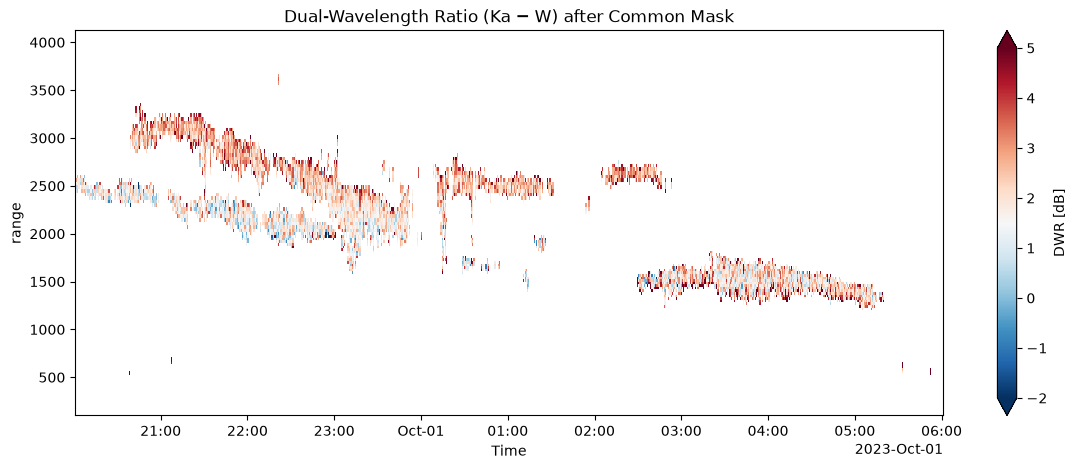

In [44]:
fig, ax = plt.subplots(figsize=(14, 5))

dwr_2km_filt.where(ds_retrieval["common_mask"]).plot(
    x="Time",
    y="range",
    cmap="RdBu_r",
    vmin=-2,
    vmax=5,
    ax=ax,
    cbar_kwargs={"label": "DWR [dB]"}
)

ax.set_title("Dual-Wavelength Ratio (Ka − W) after Common Mask")
plt.show()

 ## 2. dDWR/dH diagnostic (30 s smoothed input)



 This is the key sanity check before trusting the gradient-based retrieval: how much of the

 in-cloud gradient is still noise (negative or unphysically large |dDWR/dH|)?

In [45]:
ddwr_dh_smoothed = compute_ddwr_dh(dwr_2km_filt, ds_retrieval["cloud_mask"], N_default=9)

vals = ddwr_dh_smoothed.where(ds_retrieval["cloud_mask"]).values.ravel()
vals = vals[np.isfinite(vals)]
print("After 30 s time-averaging:")
print(f"  Fraction dDWR/dh < 0:          {(vals < 0).mean():.2%}")
print(f"  Fraction |dDWR/dh| > 30 dB/km: {(np.abs(vals) > 30).mean():.2%}")
print(f"  median dDWR/dh:                {np.median(vals):.2f} dB/km")


After 30 s time-averaging:
  Fraction dDWR/dh < 0:          47.15%
  Fraction |dDWR/dh| > 30 dB/km: 8.28%
  median dDWR/dh:                0.68 dB/km


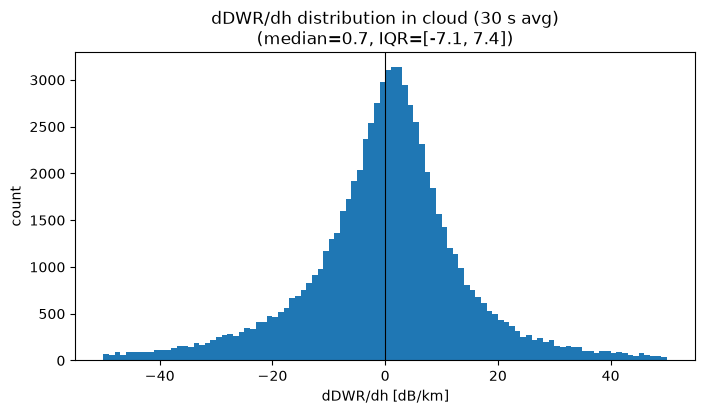

In [46]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(vals, bins=100, range=(-50, 50))
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("dDWR/dh [dB/km]")
ax.set_ylabel("count")
ax.set_title(f"dDWR/dh distribution in cloud (30 s avg)\n"
             f"(median={np.median(vals):.1f}, "
             f"IQR=[{np.percentile(vals,25):.1f}, {np.percentile(vals,75):.1f}])")
plt.show()


 (Supporting context for the guard thresholds below — per-gate DWR noise estimate from

 vertical-neighbour differences.)

In [47]:
D = dwr_2km_filt.where(ds_retrieval["common_mask"]).values                 #Filtered DWR values where the common mask is True
diffs = D[:, 1:] - D[:, :-1]                                  # DWR(i+1)−DWR(i)   Subtracting the DWR value of the next gate from the current gate to get the difference between adjacent gates
diffs = diffs[np.isfinite(diffs)]               # Remove NaN
noise_estimate = np.std(diffs) / np.sqrt(2)      #standard deviation of the difference tells how widely these differences scatter. Signal is supposed to be the same in neighbouring gates, so difference should be zero. Rest is just noise. The Variance Difference is Var(Ni+1​−Ni​)= Var(Ni+1​)+Var(Ni​) = σ^2+σ^2 =2σ^2.Therefore: Std(Ni+1​−Ni​)=sqrt(2)*σ Finally: noise = std_difference / np.sqrt(2)
print(f"Estimated per-gate DWR noise: {noise_estimate:.2f} dB")
print(f"Median in-cloud DWR:          {float(dwr_2km_filt.where(ds_retrieval['common_mask']).median()):.2f} dB")
print(f"Signal across a 9-gate (~200 m) window at 5 dB/km: {5 * 0.20:.2f} dB")    # Comparison Noise and Signal across  Window


Estimated per-gate DWR noise: 0.71 dB
Median in-cloud DWR:          2.26 dB
Signal across a 9-gate (~200 m) window at 5 dB/km: 1.00 dB


 ================================================================================================================================================================================================

 ## 3. Zhu Guarded retrieval



 Drop-in replacement for the plain gradient retrieval: overlap-averages the window fit and

 rejects windows that are too noisy (`max_window_std`) or produce an unphysical gradient

 (`max_ddwr_dh`), with `edge_pad` gates skipped near cloud base/top.

 ================================================================================================================================================================================================

In [48]:
def retrieve_lwc_zhu_guarded(
    dwr, kappa_w, kappa_ka, alpha_w, alpha_ka, common_mask,
    N_default=9,
    max_ddwr_dh=50.0,      # dB/km — physical ceiling on |dDWR/dh|
    max_window_std=3.0,    # dB    — reject noisy windows
    edge_pad=1,            # skip edge gates near cloud base/top
):
    """
    Zhu-style LWC retrieval with overlap averaging + sanity guards.
    Assumes dims ('Time', 'range'). Returns (LWC g/m^3, n_windows per gate).
    """
    h = dwr["range"].values.astype(float)
    D = dwr.values
    Kw, Kka = kappa_w.values, kappa_ka.values
    Aw, Aka = alpha_w.values, alpha_ka.values
    M = common_mask.values
    nt, nr = D.shape

    lwc_sum = np.zeros_like(D)
    lwc_cnt = np.zeros_like(D)

    for t in range(nt):
        cloud_idx = np.flatnonzero(M[t])
        if cloud_idx.size < 3:
            continue
        i0 = cloud_idx.min() + edge_pad
        i1 = cloud_idx.max() - edge_pad
        if i1 - i0 + 1 < 3:
            continue
        Nt = min(N_default, i1 - i0 + 1)

        for i in range(i0, i1 - Nt + 2):
            sl = slice(i, i + Nt)
            if not M[t, sl].all():
                continue
            dwin = D[t, sl]
            if not np.isfinite(dwin).all():
                continue
            if dwin.std() > max_window_std:
                continue
            a, b, _c = np.polyfit(h[sl], dwin, 2)
            grad = (2 * a * h[sl] + b) * 1000.0   # dB/km
            if np.any(np.abs(grad) > max_ddwr_dh):
                continue
            dkappa = Kw[t, sl] - Kka[t, sl]
            dalpha = Aw[t, sl] - Aka[t, sl]
            with np.errstate(divide="ignore", invalid="ignore"):
                lwc_win = (0.5 * grad - dalpha) / dkappa
            lwc_sum[t, sl] += lwc_win
            lwc_cnt[t, sl] += 1

    with np.errstate(invalid="ignore", divide="ignore"):
        lwc = np.where(lwc_cnt > 0, lwc_sum / lwc_cnt, np.nan)

    lwc_da = xr.DataArray(
        lwc, coords=dwr.coords, dims=dwr.dims, name="lwc",
        attrs={"units": "g m-3", "long_name": "LWC (Zhu 2019, guarded)"},
    )
    n_da = xr.DataArray(lwc_cnt, coords=dwr.coords, dims=dwr.dims, name="n_windows")
    return lwc_da, n_da

 # DONT USE CODE ABOVE HERE RIGHT NOW ANYMORE: CHANGED MY zhu.py TO BE GUARDED RETRIEVAL, SO USE THAT INSTEAD
lwc_guarded, derivative_guarded, m_eff, n_windows, n_used= retrieve_lwc_zhu( 
    dwr=dwr_2km_filt,
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    cloud_mask=ds_retrieval["common_mask"],
    N_default=9,
    min_cloud_gates=3,
    max_ddwr_dh=30.0,
    max_window_std=0.6,
    edge_pad=0
)

print(f"Gates with any retrieval: {int((n_windows > 0).sum())} "
      f"({100*float((n_windows>0).mean()):.1f}%)")
print(f"Mean windows per gate:    {float(n_windows.where(n_windows>0).mean()):.1f}")


Gates with any retrieval: 37210 (1.9%)
Mean windows per gate:    2.3


In [49]:
import inspect
print(inspect.getfile(retrieve_lwc_zhu))

C:\Projects\Masterarbeit\dual_freq_radar_lwc\src\radar_lwc\retrieval\zhu.py


In [50]:
print(retrieve_lwc_zhu)

<function retrieve_lwc_zhu at 0x00000124853089A0>


 ================================================================================================================================================================================================

 ## 4. LWC quality checks (kept: LWC<0, LWC maps, dDWR/dH already above, + 2 supporting graphs)

 ================================================================================================================================================================================================

 ### 4a. LWC < 0

In [51]:
print(f"Fraction LWC < 0: "
      f"{float((lwc_guarded < 0).sum() / lwc_guarded.notnull().sum()):.2%}")
print(f"LWC quantiles: "
      f"p05={float(lwc_guarded.quantile(0.05)):.2f}, "
      f"p50={float(lwc_guarded.quantile(0.5)):.2f}, "
      f"p95={float(lwc_guarded.quantile(0.95)):.2f} g/m^3")


Fraction LWC < 0: 48.04%
LWC quantiles: p05=-1.74, p50=0.04, p95=1.61 g/m^3


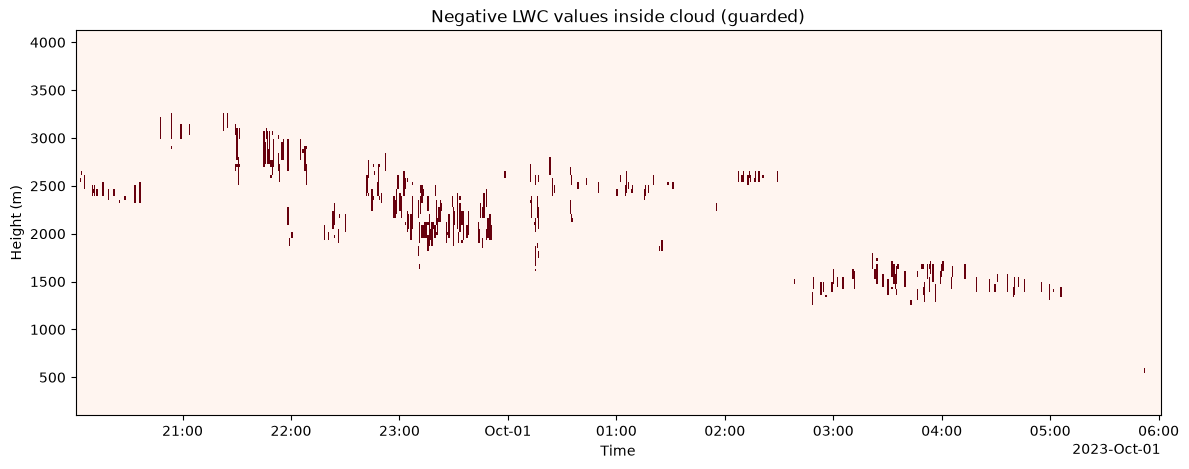

In [52]:
negative_lwc = (lwc_guarded < 0) & ds_retrieval["common_mask"]

plt.figure(figsize=(14, 5))
negative_lwc.astype(int).plot(x="Time", y="range", cmap="Reds", add_colorbar=False)
plt.title("Negative LWC values inside cloud (guarded)")
plt.xlabel("Time"); plt.ylabel("Height (m)")
plt.show()


 ### 4b. LWC map (main output)

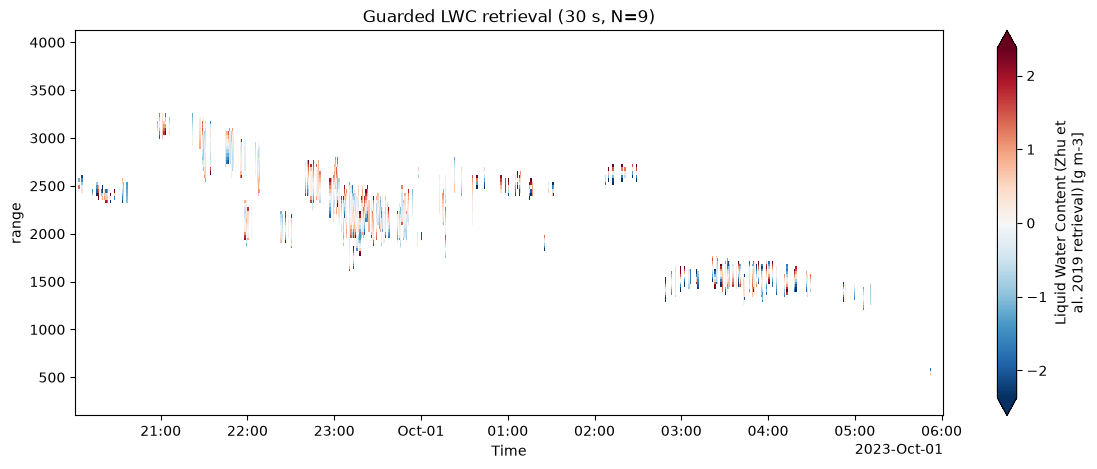

In [53]:
lwc_guarded.plot(
    x="Time", y="range", figsize=(14, 5), cmap="RdBu_r", robust=True,
)
plt.title("Guarded LWC retrieval (30 s, N=9)")
plt.show()


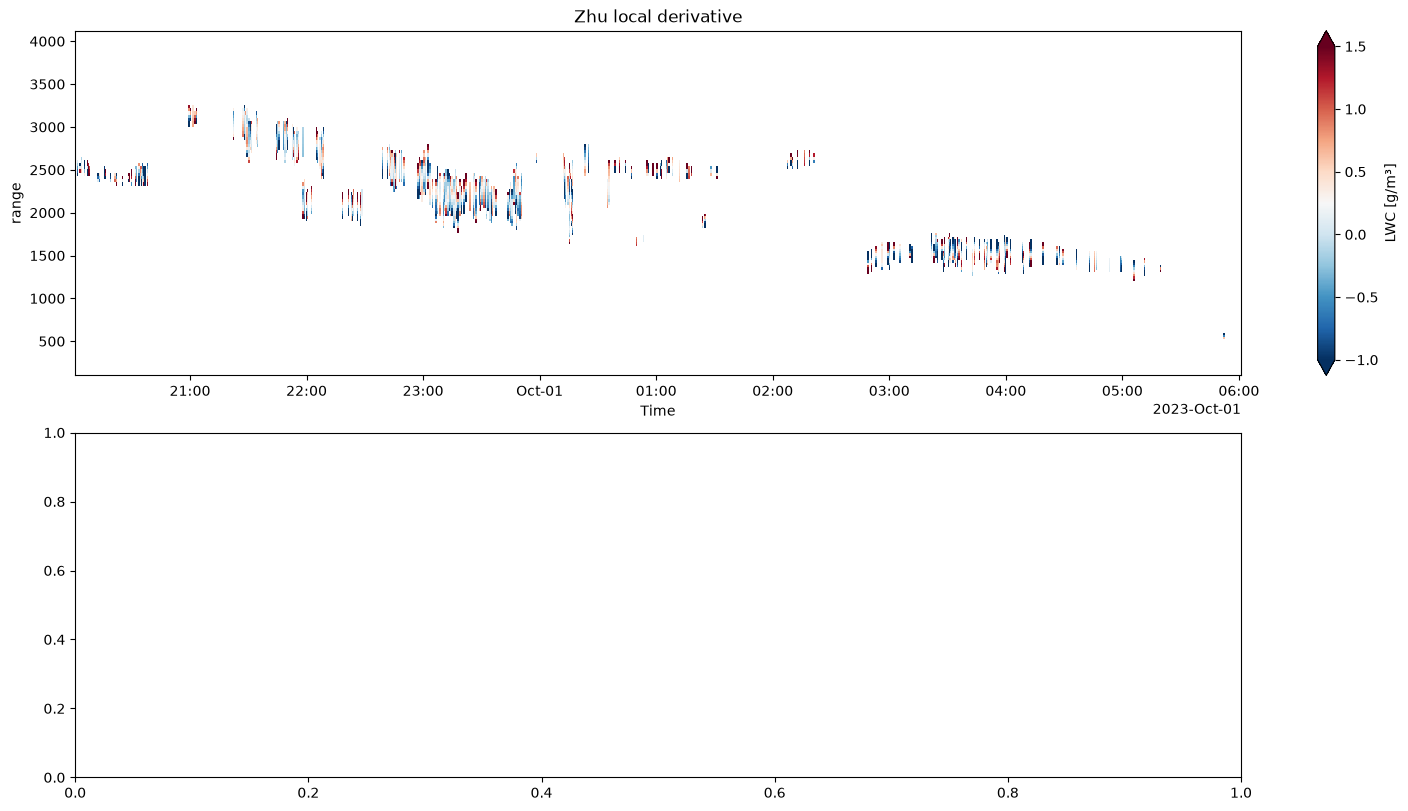

In [54]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), constrained_layout=True)
lwc_guarded.where(ds_retrieval["common_mask"]).plot(
    x="Time", y="range", ax=axes[0], vmin=-1, vmax=1.5, cmap="RdBu_r",
    cbar_kwargs={"label": "LWC [g/m³]"})
axes[0].set_title("Zhu local derivative")

plt.show()

 ### 4c. Two supporting graphs: LWC distribution + negative-gradient locations

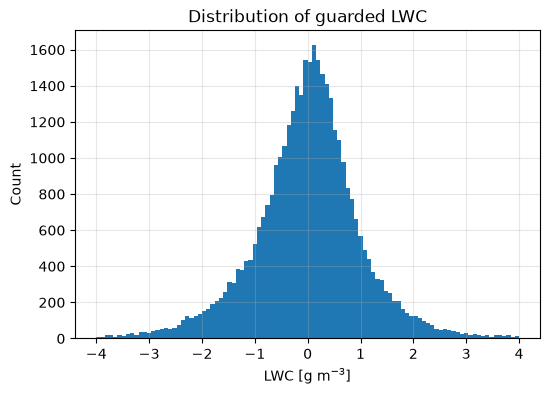

In [55]:
vals = lwc_guarded.where(ds_retrieval["common_mask"]).values
vals = vals[np.isfinite(vals)]

plt.figure(figsize=(6, 4))
plt.hist(vals, bins=100, range=(-4, 4))
plt.xlabel("LWC [g m$^{-3}$]")
plt.ylabel("Count")
plt.title("Distribution of guarded LWC")
plt.grid(alpha=0.3)
plt.show()


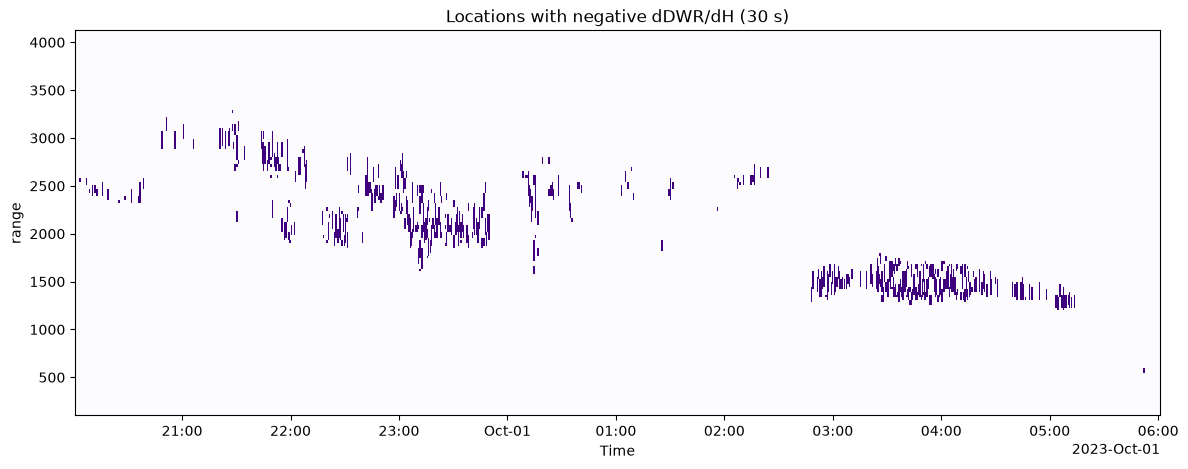

In [56]:
negative_grad = (ddwr_dh_smoothed < 0) & ds_retrieval["common_mask"]

plt.figure(figsize=(14, 5))
negative_grad.astype(int).plot(x="Time", y="range", cmap="Purples", add_colorbar=False)
plt.title("Locations with negative dDWR/dH (30 s)")
plt.show()


 ================================================================================================================================================================================================

 ## 5. LWP — kept only for later comparison (general chart, closure scatter, 3-profile spot check)

 ================================================================================================================================================================================================

 ### 5a. General LWP chart

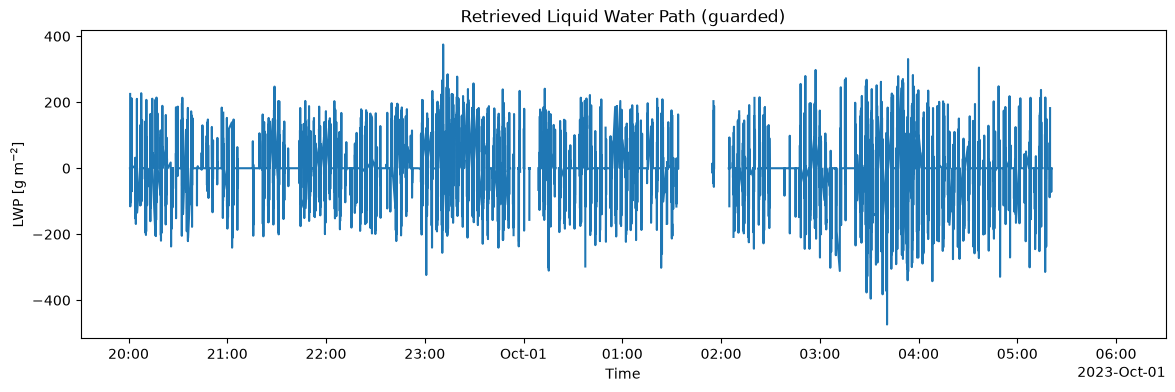

In [57]:
dr = float(dwr_2km_filt["range"].sel(range=slice(0, R_MAX_M)).diff("range").mean())
dz = dr * SIN_ELEV
lwp_guarded = (lwc_guarded.where(ds_retrieval["common_mask"]).fillna(0) * dz).sum(dim="range")
lwp_guarded = lwp_guarded.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded.attrs["units"] = "g m-2"

fig, ax = plt.subplots(figsize=(14, 4))
lwp_guarded.plot(ax=ax)
ax.set_title("Retrieved Liquid Water Path (guarded)")
ax.set_ylabel("LWP [g m$^{-2}$]")
ax.set_xlabel("Time")
plt.show()


 ### 5b. LWP closure test (scatter vs MWR)

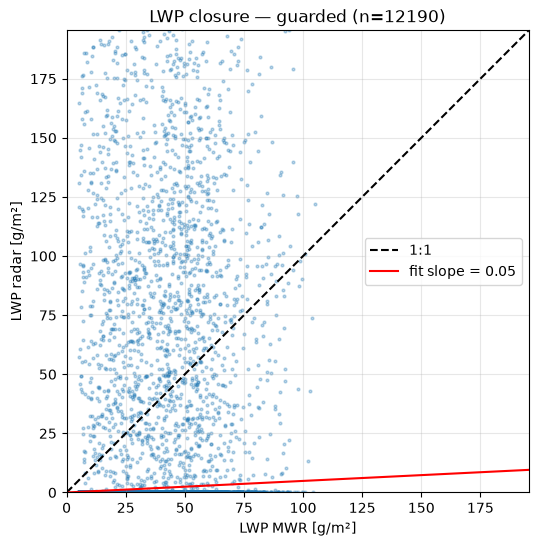

Slope through origin: 0.05   (want ~1.0)
Correlation:          0.07   (want > 0.7)
Bias:  radar - MWR = -34.0 g/m²


In [58]:
x = ds_retrieval["LWP"].values
y = lwp_guarded.values
good = np.isfinite(x) & np.isfinite(y) & (x > 5)   # ignore near-zero MWR

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded (n={good.sum()})")
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")


 ### 5c. Spot-check three profiles (kept for later comparison across methods)

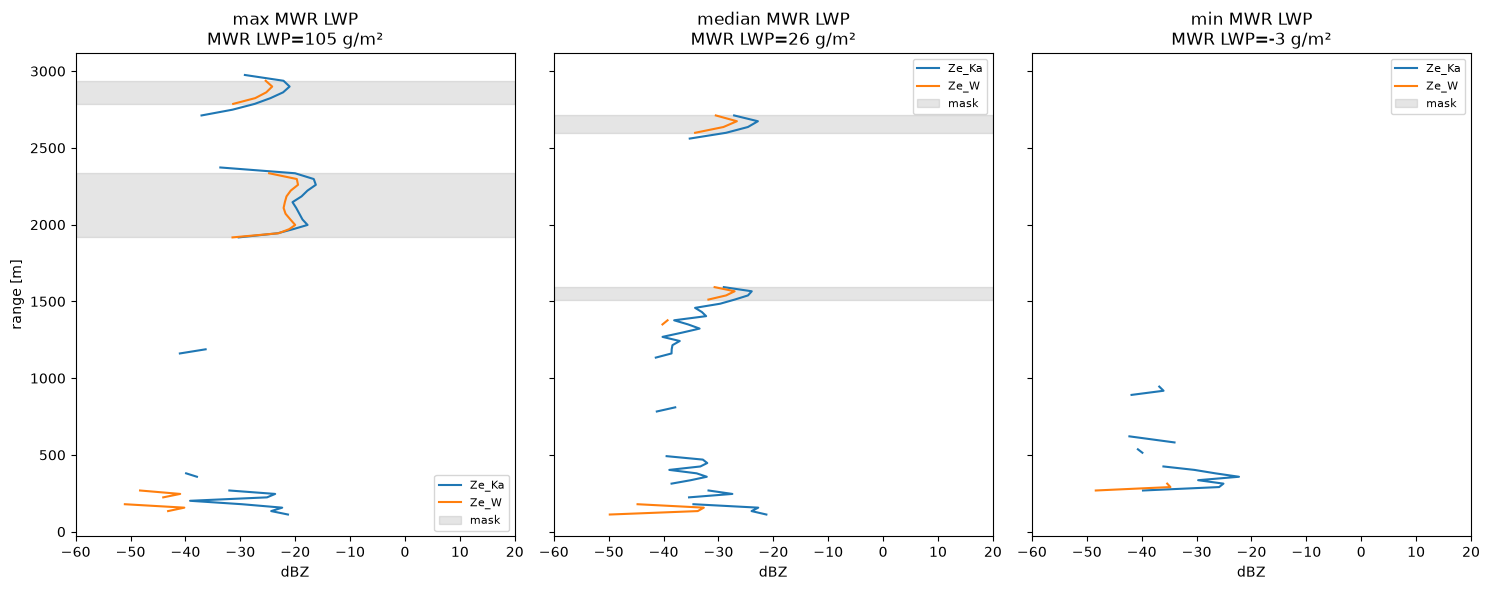

In [59]:
lwp_mwr_vals = ds_retrieval["LWP"].values
i_hi   = int(np.nanargmax(lwp_mwr_vals))
i_lo   = int(np.nanargmin(np.abs(lwp_mwr_vals - np.nanmedian(lwp_mwr_vals))))
i_zero = int(np.nanargmin(lwp_mwr_vals))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)
for ax, idx, label in zip(axes, [i_hi, i_lo, i_zero],
                          ["max MWR LWP", "median MWR LWP", "min MWR LWP"]):
    h = dwr_2km_smoothed["range"].values
    ax.plot(ds_retrieval["Ze_Ka"].sel(range=slice(0, R_MAX_M)).isel(Time=idx), h, label="Ze_Ka")
    ax.plot(ds_retrieval["Ze_W"].sel(range=slice(0, R_MAX_M)).isel(Time=idx),  h, label="Ze_W")
    mask_here = ds_retrieval["common_mask"].isel(Time=idx)
    ax.fill_betweenx(h, -60, 20, where=mask_here, color="grey", alpha=0.2, label="mask")
    ax.set_xlim(-60, 20); ax.set_xlabel("dBZ")
    ax.set_title(f"{label}\nMWR LWP={lwp_mwr_vals[idx]:.0f} g/m²")
    ax.legend(fontsize=8)
axes[0].set_ylabel("range [m]")
plt.tight_layout()
plt.show()


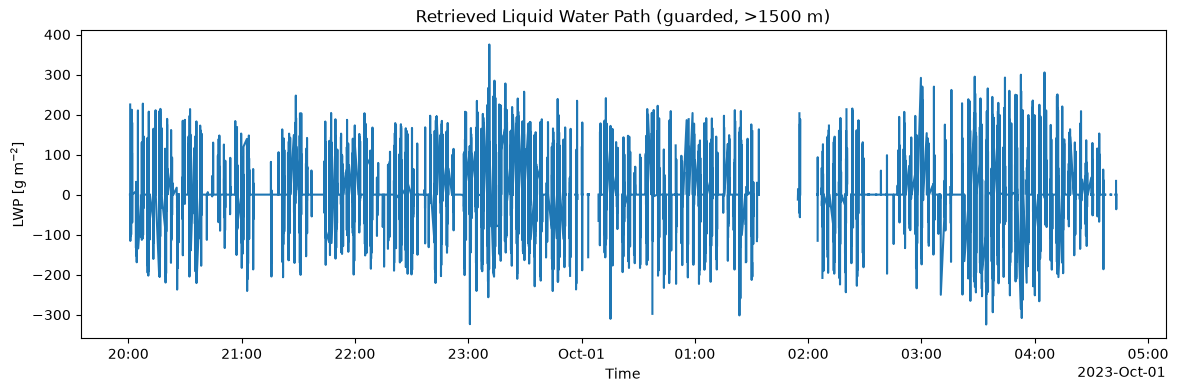

In [60]:
retrieval_mask = ds_retrieval["common_mask"] & (ds_retrieval["height"] >= 1500)

dr = float(dwr_2km_filt["range"].diff("range").mean())          # along beam
dz = dr * SIN_ELEV                                              # vertical
lwp_guarded = (lwc_guarded.where(retrieval_mask).fillna(0) * dz).sum(dim="range")

lwp_guarded = lwp_guarded.where(retrieval_mask.any(dim="range"))
lwp_guarded.attrs["units"] = "g m-2"

fig, ax = plt.subplots(figsize=(14, 4))
lwp_guarded.plot(ax=ax)
ax.set_title("Retrieved Liquid Water Path (guarded, >1500 m)")
ax.set_ylabel("LWP [g m$^{-2}$]")
ax.set_xlabel("Time")
plt.show()

In [61]:
dr = float(dwr_2km_filt["range"].sel(range=slice(0, R_MAX_M)).diff("range").mean())
dz = dr * SIN_ELEV 
lwp_guarded_1500 = (lwc_guarded.where(ds_retrieval["common_mask"]& (ds_retrieval["height"] >= 1500)).fillna(0) * dz).sum(dim="range")
lwp_guarded_1500 = lwp_guarded_1500.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded_1500.attrs["units"] = "g m-2"

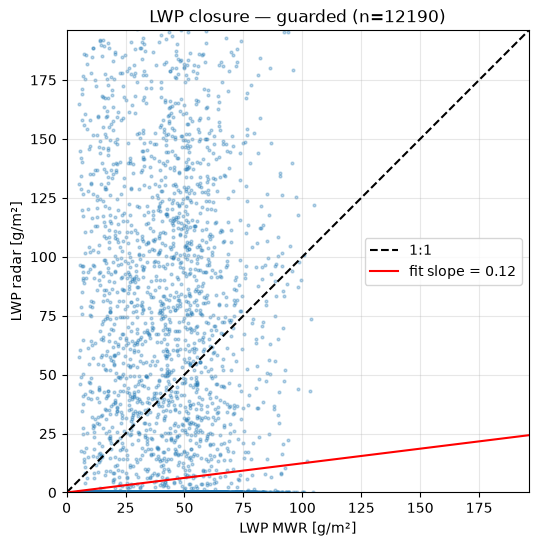

Slope through origin: 0.12   (want ~1.0)
Correlation:          0.07   (want > 0.7)
Bias:  radar - MWR = -30.7 g/m²


In [62]:
x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = np.isfinite(x) & np.isfinite(y) & (x > 5)   # ignore near-zero MWR

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded (n={good.sum()})")
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")

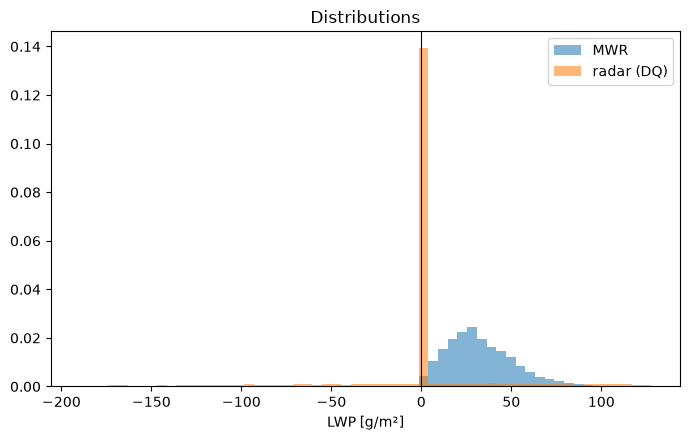

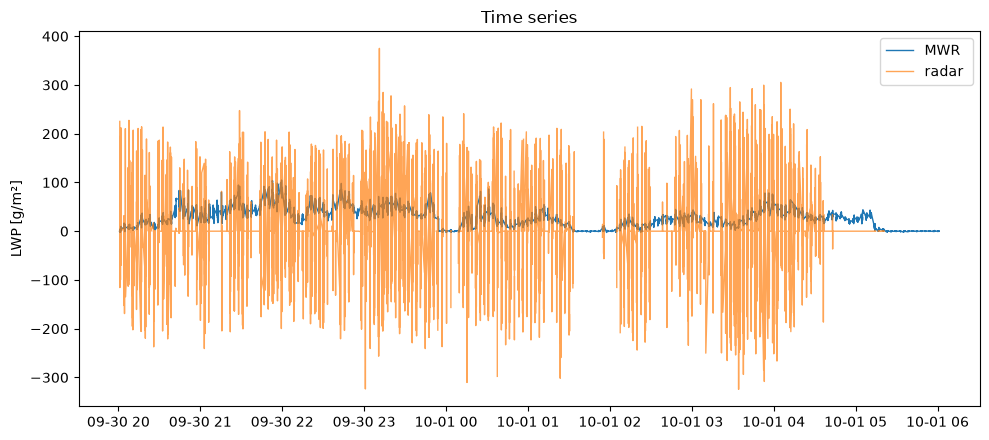

MWR   : mean   +32.7 std   18.4 p05    +6.7 p50   +29.9 p95   +67.2
radar : mean    +3.0 std   59.1 p05  -100.0 p50    +0.0 p95  +117.8


In [63]:
# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_guarded_1500.values
good = np.isfinite(x) & np.isfinite(y) #& (y > 2)

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar (DQ)", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title("Distributions")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe
plt.figure(figsize=(10, 4.5))
plt.plot(ds_retrieval["Time"], x, label="MWR", lw=1)
plt.plot(ds_retrieval["Time"], y, label="radar ", lw=1, alpha=0.7)
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

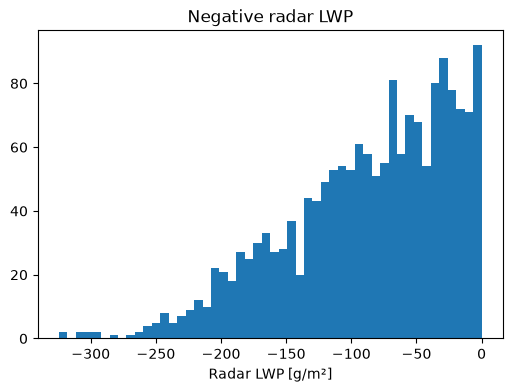

In [64]:
plt.figure(figsize=(6,4))
plt.hist(y[(y < 0) & np.isfinite(y)], bins=50)
plt.xlabel("Radar LWP [g/m²]")
plt.title("Negative radar LWP")
plt.show()

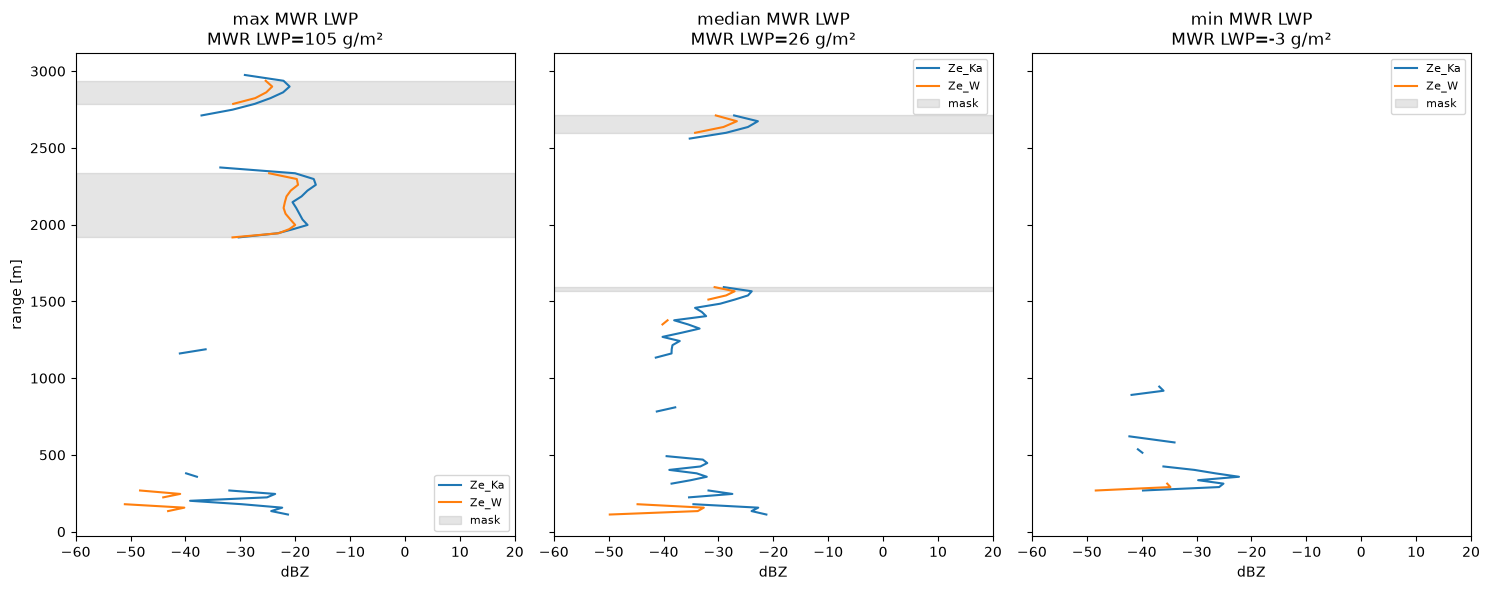

In [65]:
retrieval_mask = ds_retrieval["common_mask"] & (ds_retrieval["height"] >= 1500)

lwp_mwr_vals = ds_retrieval["LWP"].values
i_hi   = int(np.nanargmax(lwp_mwr_vals))
i_lo   = int(np.nanargmin(np.abs(lwp_mwr_vals - np.nanmedian(lwp_mwr_vals))))
i_zero = int(np.nanargmin(lwp_mwr_vals))

fig, axes = plt.subplots(1, 3, figsize=(15, 6), sharey=True)

for ax, idx, label in zip(
    axes,
    [i_hi, i_lo, i_zero],
    ["max MWR LWP", "median MWR LWP", "min MWR LWP"],
):
    h = dwr_2km_smoothed["range"].values

    ax.plot(ds_retrieval["Ze_Ka"].sel(range=slice(0, R_MAX_M)).isel(Time=idx), h, label="Ze_Ka")
    ax.plot(ds_retrieval["Ze_W"].sel(range=slice(0, R_MAX_M)).isel(Time=idx), h, label="Ze_W")

    mask_here = retrieval_mask.isel(Time=idx)

    ax.fill_betweenx(
        h, -60, 20,
        where=mask_here,
        color="grey",
        alpha=0.2,
        label="mask"
    )

    ax.set_xlim(-60, 20)
    ax.set_xlabel("dBZ")
    ax.set_title(f"{label}\nMWR LWP={lwp_mwr_vals[idx]:.0f} g/m²")
    ax.legend(fontsize=8)

axes[0].set_ylabel("range [m]")
plt.tight_layout()
plt.show()

In [66]:
# %% Export Zhu retrieval outputs for notebook 06
from pathlib import Path
import xarray as xr

ds_output_zhu = xr.Dataset(
    {
        "lwc_guarded":  lwc_guarded.rename("lwc_guarded"),
        "n_windows":    n_windows.rename("n_windows"),
        "dwr_filtered": dwr_2km_filt.rename("dwr_filtered"),
        "m_eff": m_eff.rename("m_eff"),
        "derivative_guarded": derivative_guarded.rename("derivative_guarded"),
        "n_used": n_used.rename("n_used")
        
    },
    attrs={
        "description": "Zhu et al. (2019) guarded retrieval output",
        "N_default": 9,
        "input_dwr": "30 s averaged, 1 dB despiked",
        "mask_used": "common_mask",
        "created_by": "04_zhu_guarded_retrieval_CLEANED.ipynb",
    },
)
suffix = "" if SCAN_TYPE == "zenith" else "_scan"
out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu{suffix}.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_output_zhu.to_netcdf(out_path)
print(f"Saved → {out_path}")

PermissionError: [Errno 13] Permission denied: 'c:\\Projects\\Masterarbeit\\dual_freq_radar_lwc\\data\\processed\\20230930_PPI\\retrieval_output_zhu_scan.nc'

In [ ]:
mask = ds_retrieval["common_mask"].transpose("Time", "range").values.astype(bool)

In [ ]:
def sigma_dwr(dwr_block, mask_block):
    """sigma_DWR from adjacent-gate differences, per-profile trend removed."""
    x = np.asarray(dwr_block, float).copy()
    x[~np.asarray(mask_block, bool)] = np.nan
    k = np.arange(x.shape[1], dtype=float)
    for t in range(x.shape[0]):
        g = np.isfinite(x[t])
        if g.sum() >= 3:
            x[t, g] -= np.polyval(np.polyfit(k[g], x[t, g], 1), k[g])
    d = np.diff(x, axis=1).ravel()
    d = d[np.isfinite(d)]
    return (np.sqrt(np.var(d, ddof=1)/2), d.size) if d.size > 30 else (np.nan, 0)


# mean cloud height per profile
r = ds_retrieval["range"].values
h_mid = np.array([r[np.flatnonzero(m)].max() if m.sum() >= 3 else np.nan
                  for m in mask])

edges = np.nanpercentile(h_mid, [0, 20, 40, 60, 80, 100])
centres, sigmas = [], []
for i in range(len(edges)-1):
    sel = (h_mid >= edges[i]) & (h_mid < edges[i+1])
    if sel.sum() < 30:
        continue
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    centres.append(np.nanmean(h_mid[sel])); sigmas.append(s)
    print(f"  h ~ {centres[-1]:6.0f} m : sigma {s:.3f} dB "
          f"({sel.sum()} profiles, {n} pairs)")

centres, sigmas = np.array(centres), np.array(sigmas)
if len(centres) >= 3:
    a, b = np.polyfit(1/centres, sigmas, 1)
    print(f"\nfit sigma = a/h + b  ->  a = {a:.0f} dB*m, b = {b:.3f} dB")
    print(f"predicted sigma at 750 m: {a/750+b:.3f}, "
          f"at 1400 m: {a/1400+b:.3f} dB")

  h ~   1548 m : sigma 0.782 dB (2452 profiles, 17246 pairs)
  h ~   2014 m : sigma 0.680 dB (2576 profiles, 25965 pairs)
  h ~   2545 m : sigma 0.630 dB (2433 profiles, 18558 pairs)
  h ~   2697 m : sigma 0.675 dB (2594 profiles, 22847 pairs)
  h ~   3084 m : sigma 0.652 dB (2518 profiles, 27607 pairs)

fit sigma = a/h + b  ->  a = 408 dB*m, b = 0.502 dB
predicted sigma at 750 m: 1.046, at 1400 m: 0.793 dB


In [ ]:
def sigma_dwr(dwr_block, mask_block):
    """sigma_DWR from adjacent-gate differences, per-profile trend removed."""
    x = np.asarray(dwr_block, float).copy()
    x[~np.asarray(mask_block, bool)] = np.nan
    k = np.arange(x.shape[1], dtype=float)
    for t in range(x.shape[0]):
        g = np.isfinite(x[t])
        if g.sum() >= 3:
            x[t, g] -= np.polyval(np.polyfit(k[g], x[t, g], 1), k[g])
    d = np.diff(x, axis=1).ravel()
    d = d[np.isfinite(d)]
    return (np.sqrt(np.var(d, ddof=1)/2), d.size) if d.size > 30 else (np.nan, 0)

height_mask = (r >= 700) & (r <= 1900)
dwr_2km_filt = dwr_2km_filt[:, height_mask]
mask = mask[:, height_mask]
r = r[height_mask]

# mean cloud height per profile
r = ds_retrieval["range"].values
h_mid = np.array([r[np.flatnonzero(m)].mean() if m.sum() >= 3 else np.nan
                  for m in mask])

edges = np.nanpercentile(h_mid, [0, 20, 40, 60, 80, 100])
centres, sigmas = [], []
for i in range(len(edges)-1):
    sel = (h_mid >= edges[i]) & (h_mid < edges[i+1])
    if sel.sum() < 30:
        continue
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    centres.append(np.nanmean(h_mid[sel])); sigmas.append(s)
    print(f"  h ~ {centres[-1]:6.0f} m : sigma {s:.3f} dB "
          f"({sel.sum()} profiles, {n} pairs)")

centres, sigmas = np.array(centres), np.array(sigmas)
if len(centres) >= 3:
    a, b = np.polyfit(1/centres, sigmas, 1)
    print(f"\nfit sigma = a/h + b  ->  a = {a:.0f} dB*m, b = {b:.3f} dB")
    print(f"predicted sigma at 750 m: {a/750+b:.3f}, "
          f"at 1400 m: {a/1400+b:.3f} dB")

  h ~    700 m : sigma 0.778 dB (966 profiles, 6394 pairs)
  h ~    802 m : sigma 0.721 dB (1033 profiles, 8817 pairs)
  h ~    834 m : sigma 0.747 dB (903 profiles, 8127 pairs)
  h ~    867 m : sigma 0.787 dB (1165 profiles, 10332 pairs)
  h ~   1027 m : sigma 0.761 dB (928 profiles, 5265 pairs)

fit sigma = a/h + b  ->  a = 6 dB*m, b = 0.752 dB
predicted sigma at 750 m: 0.760, at 1400 m: 0.756 dB


In [ ]:
# DWR residual after removing a smooth per-profile fit = what the retrieval calls noise
resid = np.full_like(dwr_2km_filt, np.nan)
kk = np.arange(dwr_2km_filt.shape[1], dtype=float)
for t in range(dwr_2km_filt.shape[0]):
    g = mask[t] & np.isfinite(dwr_2km_filt[t])
    if g.sum() >= 4:
        resid[t, g] = dwr_2km_filt[t, g] - np.polyval(np.polyfit(kk[g], dwr_2km_filt[t, g], 2), kk[g])

# local temporal Ze variability = proxy for small-scale spatial variability
ze = np.where(mask, ds_retrieval["Ze_W"], np.nan)
W = 5   # profiles, ~ a few seconds
loc_var = np.full_like(ze, np.nan)
for t in range(W, ze.shape[0] - W):
    loc_var[t] = np.nanstd(ze[t-W:t+W+1], axis=0)

a, b = np.abs(resid).ravel(), loc_var.ravel()
g = np.isfinite(a) & np.isfinite(b)
print(f"corr(|DWR residual|, local Ze variability) = "
      f"{np.corrcoef(a[g], b[g])[0,1]:+.3f}   (n={g.sum()})")

ValueError: operands could not be broadcast together with shapes (14993,45) (14993,130) () 

In [ ]:
import xarray as xr
import glob
Dataset_94GHz = "20230930_94GHz"
def load_rpg(folder):
     files = sorted(glob.glob(str(Path(folder) / "*ZEN.LV1.nc")))
     ds = xr.open_mfdataset(files, combine="by_coords")    # Combine="by_coords" orders them immediately by coordinates, in this case by the time so it is immediately in structure 7:01...7:02...7:03
     epoch = pd.Timestamp("2001-01-01")
     ds = ds.assign_coords(Time=("Time", epoch + pd.to_timedelta(ds.Time.values, unit="s")))
     ds = drop_duplicate_times(ds)
     return ds

raw  = load_rpg(f"../data/raw/cmtrace/{Dataset_94GHz}")

In [ ]:
print(raw["SurfWS"])

<xarray.DataArray 'SurfWS' (Time: 14915)> Size: 60kB
dask.array<getitem, shape=(14915,), dtype=float32, chunksize=(78,), chunktype=numpy.ndarray>
Coordinates:
  * Time     (Time) datetime64[ns] 119kB 2023-09-30T20:02:27 ... 2023-10-01T0...
Attributes:
    Name:     Surface wind speed from weather station
    Units:    m/s


In [ ]:
wind_speed = raw["SurfWS"].values

In [ ]:
# advection speed proxy: horizontal wind from sounding, or the Doppler
# spectrum-width / mean-velocity variability. Bin sigma_DWR by it.
for lo, hi in [(0,3), (3,6), (6,10), (10,20)]:
    sel = mask & (wind_speed[:,None] >= lo) & (wind_speed[:,None] < hi)
    s, n = sigma_dwr(dwr_2km_filt[sel], mask[sel])
    print(f"U {lo:2d}-{hi:2d} m/s : sigma {s:.3f} dB  (n={n})")

U  0- 3 m/s : sigma 0.305 dB (profiles=1036, pairs=444)
U  3- 6 m/s : sigma 0.305 dB (profiles=4608, pairs=7038)
U  6-10 m/s : sigma 0.302 dB (profiles=6975, pairs=22235)
U 10-20 m/s : sigma 0.297 dB (profiles=2296, pairs=10752)


In [ ]:
d = np.diff(np.where(mask, dwr_2km_filt, np.nan), axis=1)

edge, interior = [], []
for t in range(mask.shape[0]):
    idx = np.flatnonzero(mask[t])
    if idx.size < 6:
        continue
    lo, hi = idx[0], idx[-1]
    for k in range(lo, hi):                      # k indexes the pair (k, k+1)
        if not np.isfinite(d[t, k]):
            continue
        (edge if (k == lo or k == hi - 1) else interior).append(d[t, k])

e, i = np.array(edge), np.array(interior)
f = e.std() / i.std()
print(f"edge pairs     n={e.size:6d}  std(delta)={e.std():.3f}")
print(f"interior pairs n={i.size:6d}  std(delta)={i.std():.3f}")
print(f"f = {f:.2f}   ->  {'DROP the edge gates' if f > 1.8 else 'KEEP them'}")

ValueError: operands could not be broadcast together with shapes (14915,45) (14915,127) () 

In [ ]:
import numpy as np, xarray as xr

# dwr_2km_filt is the reference grid; everything else gets reindexed onto it.
# reindex_like matches on LABELS (Time and range values), not position.
TR      = lambda a: a.transpose("Time", "range")
target  = TR(dwr_2km_filt)
to_grid = lambda a: TR(a).reindex_like(target)

mask45 = to_grid(ds_retrieval["common_mask"]).fillna(False).astype(bool)

print(f"grid: {target.shape[0]} profiles x {target.shape[1]} gates, "
      f"{target['range'].values[0]:.0f}-{target['range'].values[-1]:.0f} m")
print(f"gate spacing: {np.median(np.diff(target['range'].values)):.1f} m")
print(f"cloudy gates: {int(mask45.sum())}")

runs = {}
for pad in (0, 1):
    lwc, ddwr, meff, nwin, nused = retrieve_lwc_zhu(
        dwr        = target,
        kappa_w    = to_grid(ds_retrieval["kappa_W"]),
        kappa_ka   = to_grid(ds_retrieval["kappa_Ka"]),
        alpha_w    = to_grid(ds_retrieval["alpha_W"]),
        alpha_ka   = to_grid(ds_retrieval["alpha_Ka"]),
        cloud_mask = mask45,
        N_default  = 9,
        edge_pad   = pad,
    )
    ds_out = xr.Dataset(
        {"lwc_guarded": lwc, "dDWR_dh": ddwr, "m_eff": meff,
         "n_windows": nwin, "N_used": nused, "dwr_filtered": target,
         "common_mask": mask45},
        attrs={"edge_pad": pad, "N_default": 9})
    ds_out.to_netcdf(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu_pad{pad}.nc")
    runs[pad] = ds_out
    print(f"edge_pad={pad}: {int(np.isfinite(lwc.values).sum())} gates retrieved")

grid: 14915 profiles x 127 gates, 112-3992 m
gate spacing: 27.0 m
cloudy gates: 127512
edge_pad=0: 85501 gates retrieved
edge_pad=1: 62459 gates retrieved


In [ ]:
m  = mask45.values
r  = target["range"].values
dr = float(np.median(np.diff(r)))
L  = {p: runs[p]["lwc_guarded"].values for p in (0, 1)}

T = np.array([np.flatnonzero(mm).size if mm.any() else 0 for mm in m])
BINS = [(3, 7), (7, 10), (10, 15), (15, 20), (20, 99)]

def row(v, tag, nprof):
    if v.size < 50:
        return f"{tag}  too few ({v.size})"
    return (f"{tag}{nprof:>9}{v.size:>8}{v.std():>8.3f}{np.median(v):>9.3f}"
            f"{(v < 0).mean():>7.0%}{(np.abs(v) > 2).mean():>8.1%}")

hdr = (f"{'T (gates)':>11}{'depth m':>9}{'profiles':>9}{'gates':>8}"
       f"{'std':>8}{'median':>9}{'<0':>7}{'|L|>2':>8}")

print("ALL GATES  (pad=0 also retrieves the outermost cloud gates)")
print(hdr)
for lo, hi in BINS:
    rows = (T >= lo) & (T < hi)
    if rows.sum() < 20:
        continue
    depth = np.median(T[rows]) * dr
    for p in (1, 0):
        v = L[p][m & rows[:, None]]; v = v[np.isfinite(v)]
        print(f"{lo:>4}-{hi:<4}p{p}{depth:>9.0f}" + row(v, "", rows.sum())[0:])
    print()

print("COMMON GATES ONLY  (identical gate population - the fair comparison)")
print(hdr)
common = np.isfinite(L[0]) & np.isfinite(L[1]) & m
for lo, hi in BINS:
    rows = (T >= lo) & (T < hi)
    sel = common & rows[:, None]
    if sel.sum() < 50:
        continue
    depth = np.median(T[rows]) * dr
    for p in (1, 0):
        v = L[p][sel]; v = v[np.isfinite(v)]
        print(f"{lo:>4}-{hi:<4}p{p}{depth:>9.0f}" + row(v, "", rows.sum())[0:])
    print()

n1, n0 = int(np.isfinite(L[1]).sum()), int(np.isfinite(L[0]).sum())
print(f"coverage: pad=1 {n1} gates | pad=0 {n0} gates (+{100*(n0/n1-1):.0f}%)")
print(f"cloudy profiles {int((T >= 3).sum())}, median thickness "
      f"{np.median(T[T>=3]):.0f} gates ({np.median(T[T>=3])*dr:.0f} m)")

ALL GATES  (pad=0 also retrieves the outermost cloud gates)
  T (gates)  depth m profiles   gates     std   median     <0   |L|>2
   3-7   p1      135     3391    5545   1.338    0.046    48%   11.1%
   3-7   p0      135     3391   14048   1.607    0.050    48%   16.5%

   7-10  p1      216     2705   10811   1.260   -0.071    53%   10.4%
   7-10  p0      216     2705   14136   1.489   -0.121    55%   15.8%

  10-15  p1      324     3922   19658   0.819    0.181    36%    3.1%
  10-15  p0      324     3922   25281   0.947    0.193    36%    4.8%

  15-20  p1      432     1985   18741   0.559    0.241    25%    1.1%
  15-20  p0      432     1985   23317   0.622    0.234    27%    1.7%

  20-99  p1      567      487    7704   0.540    0.223    28%    1.1%
  20-99  p0      567      487    8719   0.572    0.239    27%    1.5%

COMMON GATES ONLY  (identical gate population - the fair comparison)
  T (gates)  depth m profiles   gates     std   median     <0   |L|>2
   3-7   p1      135     3